<a href="https://colab.research.google.com/github/Asmae-coder455/Ant-Colony-Optimization-for-the-Traveling-Salesman-Problem-master/blob/main/dataAnalysiswithPython.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# data analytics with python

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("/products_asos.csv")
df['price'] = pd.to_numeric(df['price'], errors='coerce')
df=df.dropna(subset=['price'])
print(f"data loaded:{len(df)} raws")
print(df.head())

data loaded:18378 raws
                                                 url  \
0  https://www.asos.com/stradivarius/stradivarius...   
1  https://www.asos.com/stradivarius/stradivarius...   
2  https://www.asos.com/asos-design/asos-design-l...   
3  https://www.asos.com/new-look/new-look-trench-...   
4  https://www.asos.com/stradivarius/stradivarius...   

                                             name  \
0                   New Look trench coat in camel   
1                   New Look trench coat in camel   
2                   New Look trench coat in camel   
3                   New Look trench coat in camel   
4  Stradivarius double breasted wool coat in grey   

                                                size  \
0  UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...   
1  UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...   
2  UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...   
3  UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...   
4  XS - UK 6,S - UK 8,M - UK 10,L - UK 12

In [5]:
df['description']=df['description'].astype(str)


In [6]:
# on va faire split le size en deux partie on 'by' et on va extraire le premier mot dans la deuxieme partie correspant a la brand
def get_brand(text):
  if 'by' in text:
    try:
      return text.split('by')[1].split()[0]
    except:
      return ''
  else:
    return ''
df['brand']=df['description'].apply(get_brand)

In [7]:
print(df.head(10))

                                                 url  \
0  https://www.asos.com/stradivarius/stradivarius...   
1  https://www.asos.com/stradivarius/stradivarius...   
2  https://www.asos.com/asos-design/asos-design-l...   
3  https://www.asos.com/new-look/new-look-trench-...   
4  https://www.asos.com/stradivarius/stradivarius...   
5  https://www.asos.com/stradivarius/stradivarius...   
6  https://www.asos.com/barneys-originals/barneys...   
7  https://www.asos.com/stradivarius/stradivarius...   
8  https://www.asos.com/asos-petite/asos-design-p...   
9  https://www.asos.com/jdy/jdy-oversized-trench-...   

                                             name  \
0                   New Look trench coat in camel   
1                   New Look trench coat in camel   
2                   New Look trench coat in camel   
3                   New Look trench coat in camel   
4  Stradivarius double breasted wool coat in grey   
5  Stradivarius double breasted wool coat in grey   
6  Stradivar

In [8]:
#maping des noms de brands complets pour remplacer ceux incompletes dans la colonnes brand
brand_mapping = {
    'New': 'New Look',
    'River':'River Island',
    'Miss':'Miss Selfridge',
    'TopshopWelcome':'Topshop'
}
df['brand'] = df['brand'].map(brand_mapping).fillna(df['brand'])

In [9]:
brand_counts = df['brand'].value_counts()
print(brand_counts)
valid_brands = brand_counts[brand_counts > 5].index
df_clear = df[df['brand'].isin(valid_brands)]
print(f"data after cleaning:{len(df_clear)} raws")

brand
ASOS                      4844
Topshop                   1017
New Look                   511
River Island               474
Miss Selfridge             429
                          ... 
Help                         1
WeekdayLaid-back             1
PimkieFor                    1
WeekdayOutfit:               1
BillabongCollaboration       1
Name: count, Length: 1654, dtype: int64
data after cleaning:15896 raws


In [10]:
# function to analyze stockout
def calculate_phantom_revenue(size_str):
  if not isinstance (size_str, str):
    return 0, 0.0
  # split UK 4, UK 6, UK 8 - Out of stock
  sizes = size_str.split(',')
  total_size = len(sizes)

  # count how many items are out of stock (on met tout en minuscule avec .lower() pour éviter les erreurs de majuscules)
  out_of_stock_count = size_str.lower().count('out of stock')

  rate = out_of_stock_count / total_size if total_size > 0 else 0.0
  return total_size, rate
metrics = df_clear['size'].apply(calculate_phantom_revenue)
df_clear['total_size'] = metrics.apply(lambda x: x[0])
df_clear['out_of_stock_rate'] = metrics.apply(lambda x: x[1])
df_clear['lost_revenue'] = df_clear['price'] * df_clear['out_of_stock_rate']
print(df_clear.head())


                                                 url  \
0  https://www.asos.com/stradivarius/stradivarius...   
1  https://www.asos.com/stradivarius/stradivarius...   
2  https://www.asos.com/asos-design/asos-design-l...   
3  https://www.asos.com/new-look/new-look-trench-...   
4  https://www.asos.com/stradivarius/stradivarius...   

                                             name  \
0                   New Look trench coat in camel   
1                   New Look trench coat in camel   
2                   New Look trench coat in camel   
3                   New Look trench coat in camel   
4  Stradivarius double breasted wool coat in grey   

                                                size  \
0  UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...   
1  UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...   
2  UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...   
3  UK 4,UK 6,UK 8,UK 10,UK 12,UK 14 - Out of stoc...   
4  XS - UK 6,S - UK 8,M - UK 10,L - UK 12,XL - UK 14   

       

/tmp/ipykernel_899/1860381503.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clear['total_size'] = metrics.apply(lambda x: x[0])
/tmp/ipykernel_899/1860381503.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clear['out_of_stock_rate'] = metrics.apply(lambda x: x[1])
/tmp/ipykernel_899/1860381503.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https

In [11]:
brand_strategy = df_clear.groupby('brand')['lost_revenue'].sum().sort_values(ascending=False)
print(brand_strategy)

brand
ASOS                    58725.698438
Topshop                 11459.234192
River Island             6210.480952
New Look                 5813.813171
The                      5795.885714
                            ...     
Amy                         0.000000
ObjectYour                  0.000000
MonkiWork-to-weekend        0.000000
HIITRep                     0.000000
We                          0.000000
Name: lost_revenue, Length: 337, dtype: float64


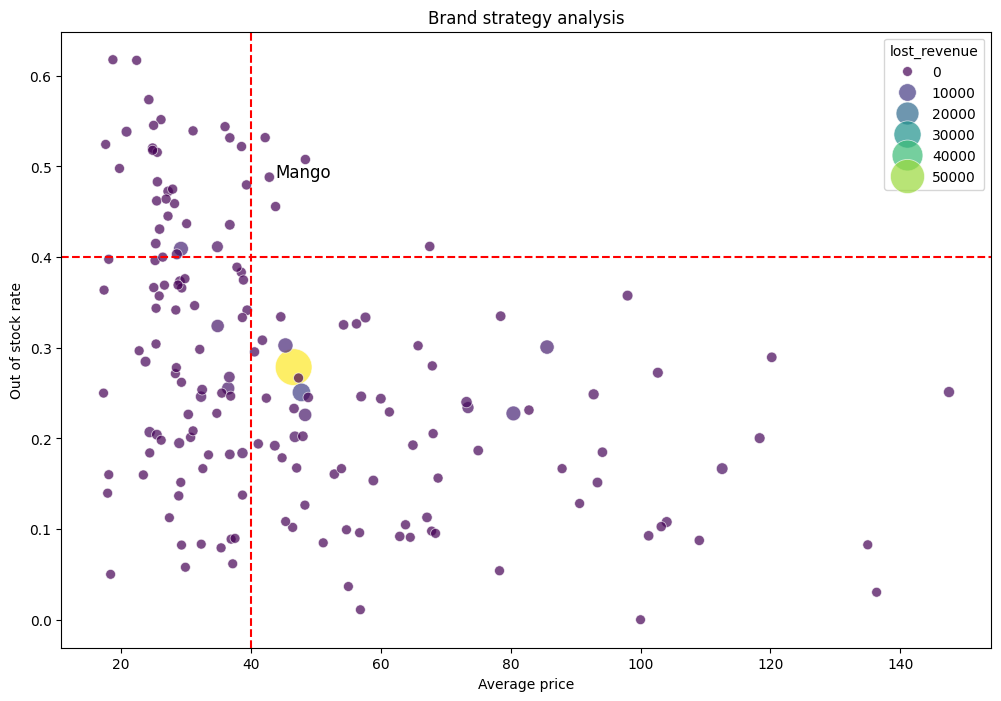

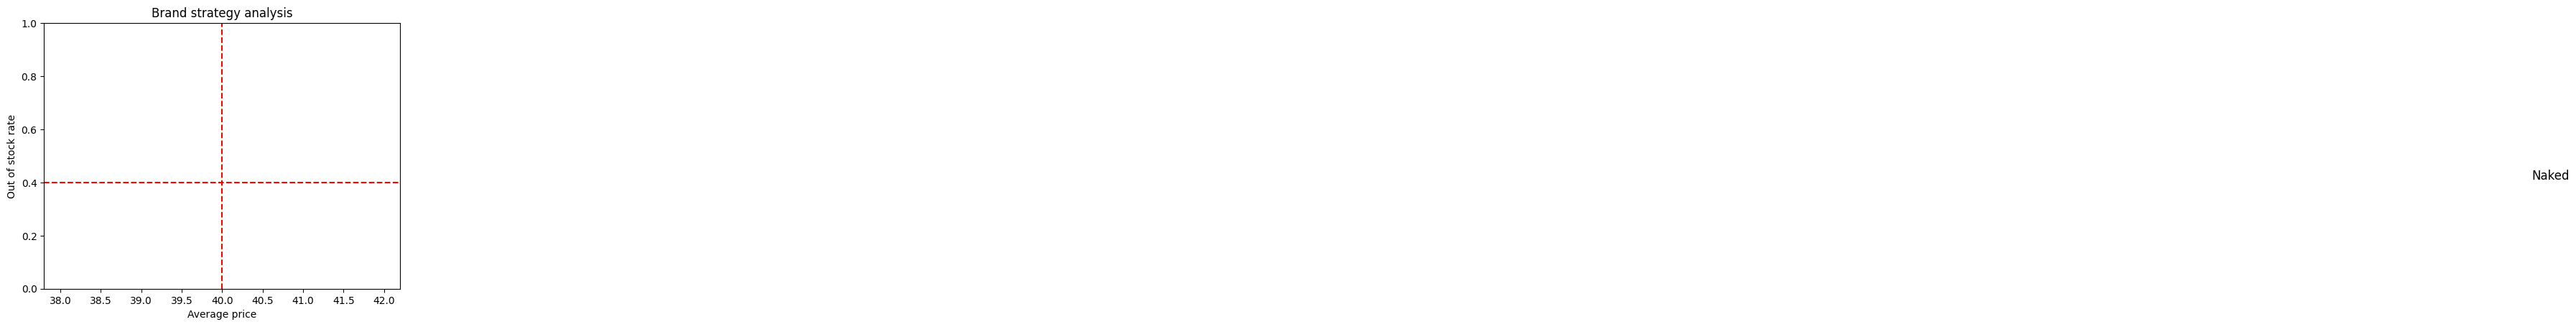

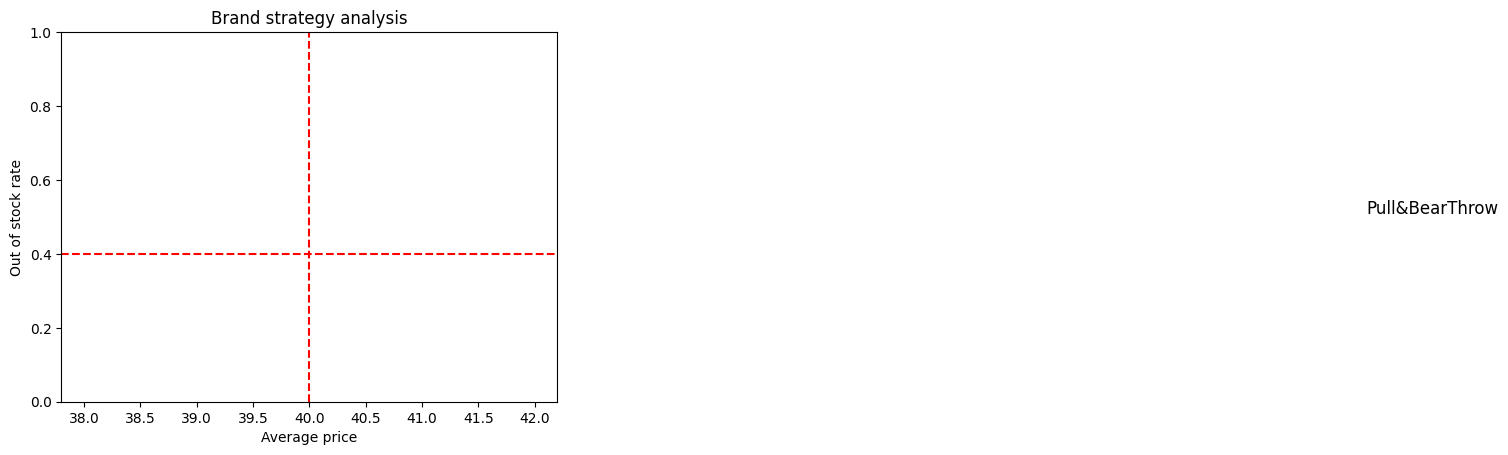

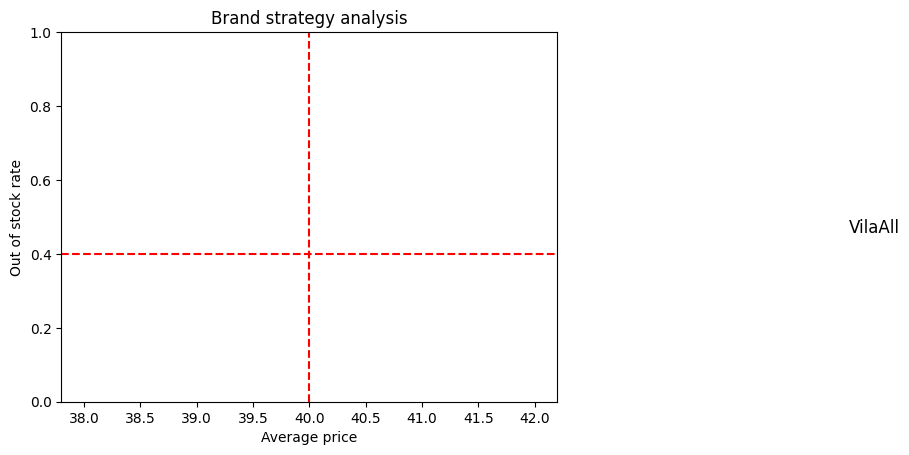

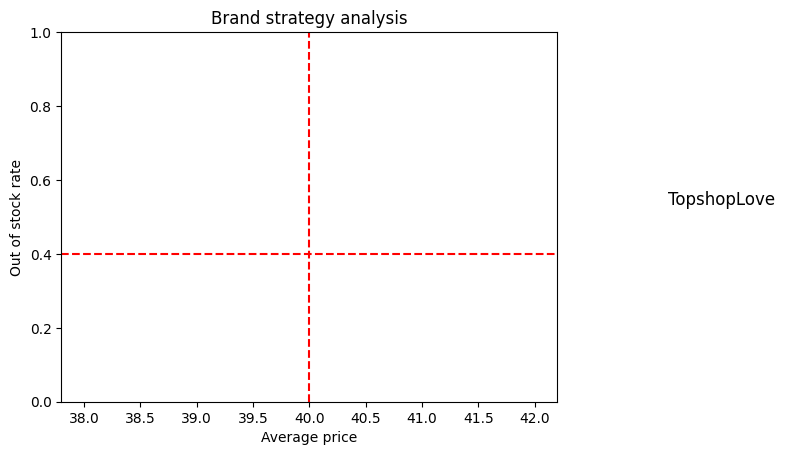

In [15]:
brand_strategy = df_clear.groupby('brand').agg({
    'price': 'mean',
    'out_of_stock_rate':'mean',
    'lost_revenue': 'sum',
    'name':'count'
}).sort_values(by='lost_revenue', ascending=False).reset_index()
brand_strategy = brand_strategy[brand_strategy['name']>10]
plt.figure(figsize=(12,8))
sns.scatterplot(data=brand_strategy, x='price', y='out_of_stock_rate', hue='lost_revenue', size='lost_revenue', sizes=(50,700), alpha=0.7, palette='viridis')
winners=brand_strategy[
    (brand_strategy['price']>40) &
    (brand_strategy['out_of_stock_rate']>0.4)
]
for i in range(len(winners)):
  plt.text(
      x=winners.iloc[i]['price']+1,
      y=winners.iloc[i]['out_of_stock_rate'],
      s=winners.iloc[i]['brand'],
      fontsize=12,
  )
  plt.title('Brand strategy analysis')
  plt.xlabel('Average price')
  plt.ylabel('Out of stock rate')
  plt.axvline(x=40, color='red', linestyle='--')
  plt.axhline(y=0.4, color='red', linestyle='--')
  plt.show()